# 1. Read the file

In [10]:
from pathlib import Path
import pandas as pd

# need to change to the real path
folder = Path("/Users/densoul/Desktop/600")
input_file = folder / "cleaned_latest_data.csv"

data = pd.read_csv(
    input_file,
    dtype={"Participant ID": "string"},
    low_memory=False,
)

data.columns = data.columns.str.strip()

print(f"Records: {len(data):,}")
display(data.head())

Records: 13,053


,Participant ID,Survey year,Immediate recall,Delayed recall,Serial 7s,Backwards counting,Derived 0-27 cognition score,Hypertension,Diabetes,Cancer,...,Chronic Disease Burden,Age,Sex,Race/ethnicity,Education,Marital status,Smoking,BMI,Interview mode,Proxy respondent
0,010001010,2022,4.0,0.0,5.0,2.0,11.0,0.0,0.0,0.0,...,0.0,83.0,1,Non-Hispanic White,12.0,8.0,0.0,19.5,1.0,0.0
1,010003030,2022,5.0,2.0,4.0,2.0,13.0,1.0,0.0,0.0,...,5.0,66.0,2,Non-Hispanic White,16.0,7.0,0.0,36.0,1.0,0.0
2,010004040,2022,7.0,5.0,5.0,2.0,19.0,1.0,0.0,0.0,...,2.0,77.0,2,Non-Hispanic White,12.0,1.0,0.0,30.1,1.0,0.0
3,010013040,2022,5.0,6.0,5.0,2.0,18.0,1.0,0.0,0.0,...,1.0,74.0,2,Non-Hispanic White,13.0,5.0,0.0,25.2,1.0,0.0
4,010038010,2022,4.0,4.0,5.0,2.0,15.0,1.0,0.0,0.0,...,2.0,85.0,1,Non-Hispanic White,16.0,1.0,0.0,22.8,1.0,0.0


# 2.Redefine the numerical codes for each race category

In [11]:
race_mapping = {
    "Non-Hispanic White": 0,
    "Non-Hispanic Other": 1,
    "Non-Hispanic Black": 2,
    "Hispanic": 3,
}

race = data["Race/ethnicity"].astype("string").str.strip()

invalid = race.isna() | ~race.isin(race_mapping)
if invalid.any():
    raise ValueError(
        f"Missing or unexpected race values: "
        f"{race.loc[invalid].unique().tolist()}"
    )

data["Race/ethnicity"] = race.map(race_mapping).astype("int64")

print("Race/ethnicity counts after recoding:")
print(data["Race/ethnicity"].value_counts().sort_index())

Race/ethnicity counts after recoding:
Race/ethnicity
0    8186
1     375
2    2616
3    1876
Name: count, dtype: int64


In [12]:
print("Data types:")
print(data.dtypes)

non_numeric = data.select_dtypes(exclude="number").columns.tolist()
print("\nNon-numeric columns:", non_numeric)

model_columns = data.drop(columns=["Participant ID"])

print(
    "\nAll remaining columns are numeric:",
    model_columns.select_dtypes(exclude="number").empty,
)

Data types:
Participant ID                   string
Survey year                       int64
Immediate recall                float64
Delayed recall                  float64
Serial 7s                       float64
Backwards counting              float64
Derived 0-27 cognition score    float64
Hypertension                    float64
Diabetes                        float64
Cancer                          float64
Chronic lung disease            float64
Heart disease                   float64
Stroke                          float64
Arthritis                       float64
Chronic Disease Burden          float64
Age                             float64
Sex                               int64
Race/ethnicity                    int64
Education                       float64
Marital status                  float64
Smoking                         float64
BMI                             float64
Interview mode                  float64
Proxy respondent                float64
dtype: object

Non-numeric c

# 3.Pre-processing
## Define X1 and X2

In [13]:
demographic_features = [ "Age", "Sex", "Race/ethnicity", "Education", "Marital status"]

health_features = ["Smoking","BMI"]

# Model 1: Demographics + health condition
x1_features = demographic_features + health_features

# Model 2: Demographics + health condition + Chronic Disease Burden
x2_features = x1_features + ["Chronic Disease Burden"]

X1 = data[x1_features].copy()
X2 = data[x2_features].copy()

print("Model 1 features:", X1.columns.tolist())
print("Model 1 shape:", X1.shape)

print("\nModel 2 features:", X2.columns.tolist())
print("Model 2 shape:", X2.shape)


Model 1 features: ['Age', 'Sex', 'Race/ethnicity', 'Education', 'Marital status', 'Smoking', 'BMI']
Model 1 shape: (13053, 7)

Model 2 features: ['Age', 'Sex', 'Race/ethnicity', 'Education', 'Marital status', 'Smoking', 'BMI', 'Chronic Disease Burden']
Model 2 shape: (13053, 8)


## Define Y

In [14]:
# Outcome: Cognitive Score (0–27)
Y = data["Derived 0-27 cognition score"].copy()

print("Outcome:",Y.name)
print("Shape:", Y.shape)
print("Missing values:", Y.isna().sum())
print("Score range:", Y.min(), "to", Y.max())

assert X1.index.equals(Y.index)
assert X2.index.equals(Y.index)

Outcome: Derived 0-27 cognition score
Shape: (13053,)
Missing values: 0
Score range: 0.0 to 27.0


## Split the Data into Training and Test Sets

Use `train_test_split()` to divide the data into 70% training and 30% test sets.

- **X1:** Demographics + health condition (Model 1).
- **X2:** Demographics + health condition + Chronic Disease Burden (Model 2).
- **y:** Cognitive Score (0–27).

Split X1, X2, and y together so both models use the same participants in their training and test sets. Set `shuffle=True` to shuffle the records before splitting and `random_state=3` to make the split reproducible.

Use the training set to fit the models and the test set to evaluate and compare their predictive performance. Fit any preprocessing steps on the training set only, then apply them to the test set.

In [15]:
from sklearn.model_selection import train_test_split

(X1_trainset,X1_testset,X2_trainset,X2_testset,Y_trainset,Y_testset,) = train_test_split(
    X1,X2,Y, test_size=0.3,random_state=3,shuffle=True,)

# Check that both models use the same records
assert X1_trainset.index.equals(X2_trainset.index)
assert X1_trainset.index.equals(Y_trainset.index)
assert X1_testset.index.equals(X2_testset.index)
assert X1_testset.index.equals(Y_testset.index)

print("X1 training set:", X1_trainset.shape)
print("X1 test set:", X1_testset.shape)
print("X2 training set:", X2_trainset.shape)
print("X2 test set:", X2_testset.shape)
print("y training set:", Y_trainset.shape)
print("y test set:", Y_testset.shape)

X1 training set: (9137, 7)
X1 test set: (3916, 7)
X2 training set: (9137, 8)
X2 test set: (3916, 8)
y training set: (9137,)
y test set: (3916,)


导入需要用到的library

In [16]:
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Step 2 — Check the Training and Test Data

Confirm that X1, X2, and Y contain the same participants in the same order within each set. Check for missing or infinite values and ensure that training and test records do not overlap.

In [17]:
# Check that predictors and outcomes are aligned
assert X1_trainset.index.equals(X2_trainset.index)
assert X1_trainset.index.equals(Y_trainset.index)

assert X1_testset.index.equals(X2_testset.index)
assert X1_testset.index.equals(Y_testset.index)

# Check for missing or infinite values
datasets = {
    "X1_trainset": X1_trainset,
    "X2_trainset": X2_trainset,
    "Y_trainset": Y_trainset,
    "X1_testset": X1_testset,
    "X2_testset": X2_testset,
    "Y_testset": Y_testset,
}

for name, dataset in datasets.items():
    if not np.isfinite(dataset.to_numpy(dtype=float)).all():
        raise ValueError(f"{name} contains missing or infinite values.")

# Check that training and test records do not overlap
assert X1_trainset.index.intersection(X1_testset.index).empty

print("All checks passed.")
print(f"Training records: {len(Y_trainset):,}")
print(f"Test records: {len(Y_testset):,}")

All checks passed.
Training records: 9,137
Test records: 3,916


## Step 3 — Define Preprocessing Rules

Use one-hot encoding for Sex, Race/ethnicity, Marital status, and Smoking. Omit one reference category for each variable to avoid redundant columns in linear regression.

Keep Age, Education, BMI, and Chronic Disease Burden in their original numerical units.

This step defines the preprocessing rules. The encoder will learn categories from the training data when the model is fitted.

In [18]:
categorical_features = ["Sex","Race/ethnicity", "Marital status", "Smoking"]

numerical_features_m1 = ["Age", "Education", "BMI"]

numerical_features_m2 = numerical_features_m1 + ["Chronic Disease Burden"]

def make_preprocessor(numerical_features):
    return ColumnTransformer(
        transformers=[
            (
                "categorical",
                OneHotEncoder(
                    drop="first",
                    handle_unknown="error",
                ),
                categorical_features,
            ),
            (
                "numerical",
                "passthrough",
                numerical_features,
            ),
        ]
    )

## Step 4 — Build the Multiple Linear Regression Models

Create a pipeline for each model that combines preprocessing with linear regression.

- Model 1 uses Demographics, Smoking, and BMI.
- Model 2 includes the same predictors plus Chronic Disease Burden.

This step creates the models. Training will be performed in the next step.

In [19]:
mlr_model1 = Pipeline(
    steps=[ ("preprocessor", make_preprocessor(numerical_features_m1)),
            ("regression", LinearRegression())])

mlr_model2 = Pipeline(
    steps=[ ("preprocessor", make_preprocessor(numerical_features_m2)),
            ("regression", LinearRegression())])

print("Model 1 and Model 2 are ready for training.")

Model 1 and Model 2 are ready for training.


## Step 5 — Train Model 1

Fit Model 1 using X1_trainset and Y_trainset.

The pipeline first learns the categorical encoding from the training data, then fits the linear regression to predict Cognitive Score using demographics, Smoking, and BMI.

The test set is reserved for later evaluation.

In [20]:
mlr_model1.fit(X1_trainset, Y_trainset)

print("Model 1 training completed.")

Model 1 training completed.


## Step 6 — Train Model 2

Fit Model 2 using X2_trainset and Y_trainset.

Model 2 uses the same training participants and outcome as Model 1, with Chronic Disease Burden added to the predictors. Each model estimates its own regression coefficients.

In [21]:
mlr_model2.fit(X2_trainset, Y_trainset)

print("Model 2 training completed.")

Model 2 training completed.


## Step 7 — Predict Cognitive Scores on the Test Set

Use the trained models to predict Cognitive Scores for the same test participants.

Model 1 uses X1_testset, and Model 2 uses X2_testset. Apply the encoding learned during training without refitting.

Display the predictions alongside the actual scores in Y_testset.

In [22]:
Y_pred_m1 = mlr_model1.predict(X1_testset)
Y_pred_m2 = mlr_model2.predict(X2_testset)

prediction_results = pd.DataFrame(
    {
        "Actual Cognitive Score": Y_testset,
        "Model 1 Prediction": Y_pred_m1,
        "Model 2 Prediction": Y_pred_m2,
    },
    index=Y_testset.index,
)

display(prediction_results.head(10))

,Actual Cognitive Score,Model 1 Prediction,Model 2 Prediction
3277,15.0,13.185083,13.229661
1411,8.0,12.644534,12.600094
2877,14.0,12.513470,13.180042
4242,16.0,14.343114,14.548326
8473,18.0,17.351489,17.774374
9176,12.0,16.060401,15.834852
11635,10.0,14.831036,15.415940
7962,18.0,16.262606,16.079002
8378,16.0,15.904767,15.829486
4227,12.0,15.927218,16.413508


## Step 8 — Evaluate Model Performance

Compare predicted Cognitive Scores with the actual values in Y_testset.

Calculate MAE, RMSE, and R² for both models on the same test set. Lower MAE and RMSE indicate better predictions, while higher R² indicates better performance.

Compare Model 1 and Model 2 to assess whether adding Chronic Disease Burden improves test-set prediction.

In [23]:
def evaluate_regression(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R²": r2_score(actual, predicted),
    }

mlr_results = pd.DataFrame(
    [
        evaluate_regression(Y_testset, Y_pred_m1),
        evaluate_regression(Y_testset, Y_pred_m2),
    ],
    index=["Model 1", "Model 2"],
)

display(mlr_results.round(4))

,MAE,RMSE,R²
Model 1,3.3485,4.2256,0.2818
Model 2,3.3383,4.2133,0.2860


## Step 9 — Visualize Actual and Predicted Cognitive Scores

Plot actual Cognitive Scores against predicted scores for each model using the same test participants and axis scales.

Each point represents one participant. The dashed diagonal line represents perfect prediction. Points closer to this line indicate smaller prediction errors.

Compare the two panels to examine whether adding Chronic Disease Burden improves prediction.

Matplotlib is building the font cache; this may take a moment.


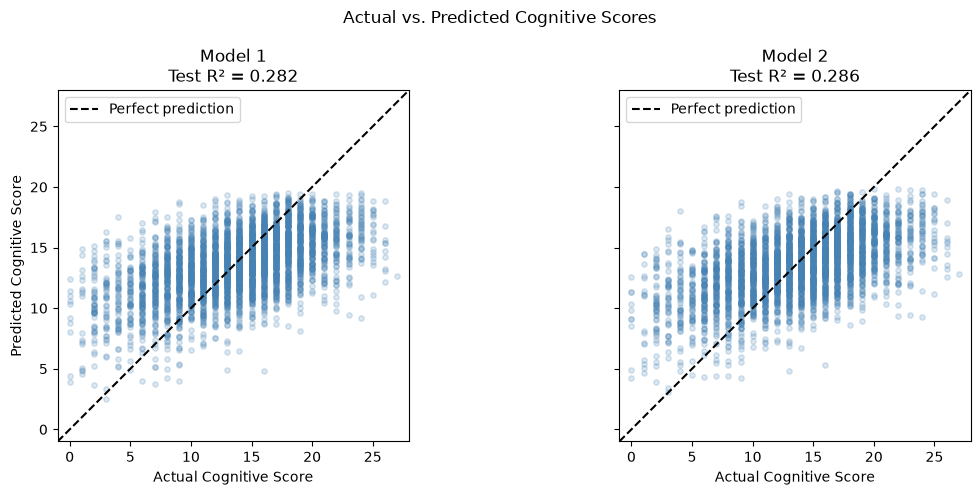

Figure saved to: /Users/densoul/Desktop/600/mlr_actual_vs_predicted.png


In [24]:
import matplotlib.pyplot as plt

# Use the same axis range for both models
lower = min(
    0,
    Y_testset.min(),
    Y_pred_m1.min(),
    Y_pred_m2.min(),
) - 1

upper = max(
    27,
    Y_testset.max(),
    Y_pred_m1.max(),
    Y_pred_m2.max(),
) + 1

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5),
    sharex=True,
    sharey=True,
)

for ax, name, predictions in [
    (axes[0], "Model 1", Y_pred_m1),
    (axes[1], "Model 2", Y_pred_m2),
]:
    ax.scatter(
        Y_testset,
        predictions,
        alpha=0.2,
        s=15,
        color="steelblue",
    )

    ax.plot(
        [lower, upper],
        [lower, upper],
        "--",
        color="black",
        label="Perfect prediction",
    )

    ax.set_xlim(lower, upper)
    ax.set_ylim(lower, upper)
    ax.set_aspect("equal", adjustable="box")

    ax.set_xlabel("Actual Cognitive Score")
    ax.set_title(
        f"{name}\nTest R² = {mlr_results.loc[name, 'R²']:.3f}"
    )
    ax.legend()

axes[0].set_ylabel("Predicted Cognitive Score")

fig.suptitle("Actual vs. Predicted Cognitive Scores")
fig.tight_layout()

figure_file = folder / "mlr_actual_vs_predicted.png"
fig.savefig(figure_file, dpi=300, bbox_inches="tight")

plt.show()
print(f"Figure saved to: {figure_file}")

## Step 10 — Plot Residuals

Calculate residuals as actual minus predicted Cognitive Scores.

Plot residuals against predicted scores for both models using the same axis scales. The horizontal line at zero represents no prediction error.

Look for residuals scattered around zero without a clear curve or changing spread. Such patterns can help identify systematic prediction errors.

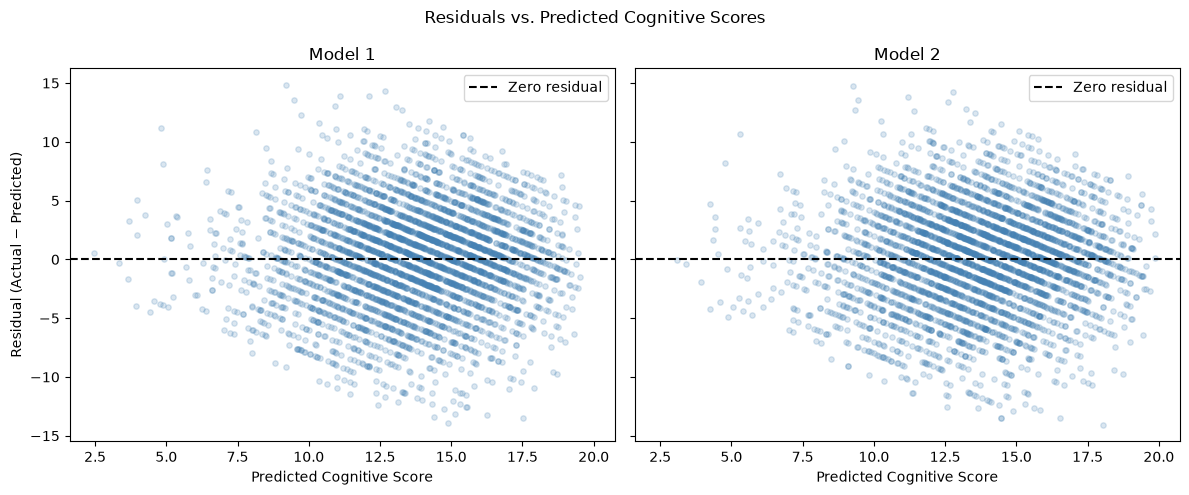

Figure saved to: /Users/densoul/Desktop/600/mlr_residual_plots.png


In [25]:
# Calculate residuals
residuals_m1 = Y_testset - Y_pred_m1
residuals_m2 = Y_testset - Y_pred_m2

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5),
    sharex=True,
    sharey=True,
)

for ax, name, predictions, residuals in [
    (axes[0], "Model 1", Y_pred_m1, residuals_m1),
    (axes[1], "Model 2", Y_pred_m2, residuals_m2),
]:
    ax.scatter(
        predictions,
        residuals,
        alpha=0.2,
        s=15,
        color="steelblue",
    )

    ax.axhline(
        y=0,
        linestyle="--",
        color="black",
        label="Zero residual",
    )

    ax.set_xlabel("Predicted Cognitive Score")
    ax.set_title(name)
    ax.legend()

axes[0].set_ylabel("Residual (Actual − Predicted)")

fig.suptitle("Residuals vs. Predicted Cognitive Scores")
fig.tight_layout()

figure_file = folder / "mlr_residual_plots.png"
fig.savefig(figure_file, dpi=300, bbox_inches="tight")

plt.show()
print(f"Figure saved to: {figure_file}")